
Extract and clean country info (titles can have several countries -> explode)

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
os.makedirs("charts", exist_ok=True)

In [29]:
df=pd.read_csv("netflix_clean.csv",encoding="latin-1")

In [30]:
countries=df[["show_id","type","country"]].copy()
countries["country"]=countries["country"].str.split(", ")
countries=countries.explode("country")
countries["country"]=countries["country"].str.strip()
countries=countries[(countries["country"]!="")&(countries["country"]!="Unknown")]


content count by country

In [31]:
country_count=countries.groupby("country").size().sort_values(ascending=False)

Top content_producing country

In [32]:
top10=country_count.head(10)
print("Top 10 countries:\n",top10)

Top 10 countries:
 country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
dtype: int64


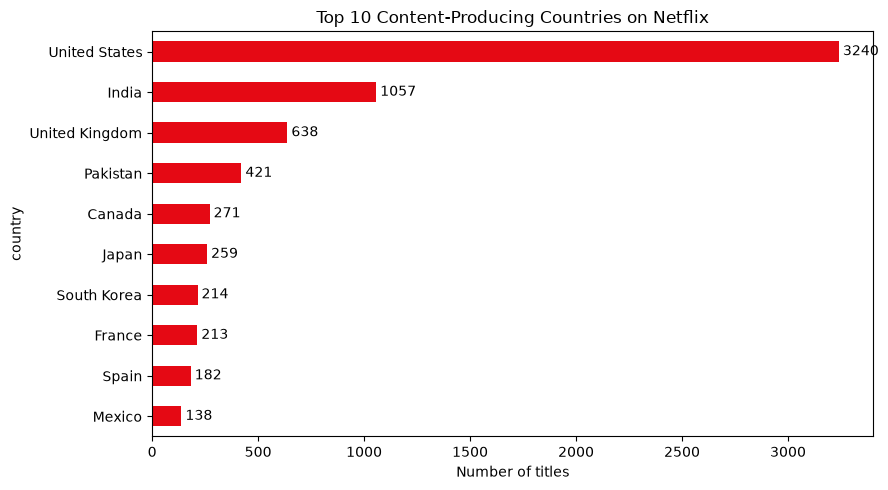

In [33]:
plt.figure(figsize=(9, 5))
top10.sort_values().plot(kind="barh", color="#E50914")
plt.title("Top 10 Content-Producing Countries on Netflix")
plt.xlabel("Number of titles")
for i, v in enumerate(top10.sort_values()):
    plt.text(v, i, f" {v}", va="center")
plt.tight_layout()
plt.savefig("charts/task3_top_countries.png", dpi=150)
plt.show()

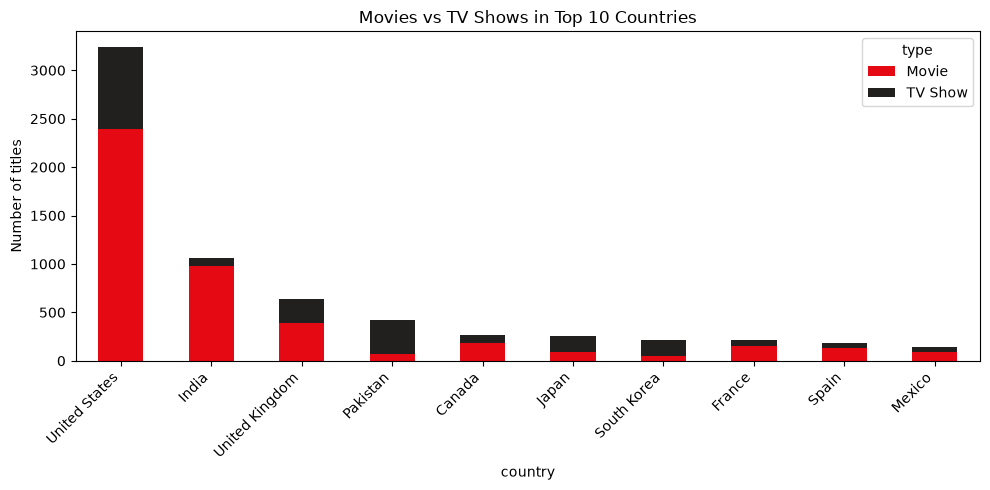

In [34]:
by_type = (countries[countries["country"].isin(top10.index)]
           .groupby(["country", "type"]).size().unstack(fill_value=0)
           .loc[top10.index])
by_type.plot(kind="bar", stacked=True, figsize=(10, 5), color=["#E50914", "#221F1F"])
plt.title("Movies vs TV Shows in Top 10 Countries")
plt.ylabel("Number of titles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("charts/task3_country_by_type.png", dpi=150)
plt.show()

In [35]:
ranking = country_count.reset_index()
ranking.columns = ["Country", "Titles"]
ranking["Rank"] = ranking["Titles"].rank(ascending=False, method="min").astype(int)
ranking["Share %"] = (ranking["Titles"] / ranking["Titles"].sum() * 100).round(2)
ranking.to_csv("country_ranking_report.csv", index=False)

In [36]:
top_n = ranking.iloc[0]
top3_share = ranking.head(3)["Share %"].sum().round(1)
print(f"\nINSIGHTS: {top_n['Country']} leads with {top_n['Titles']} titles "
      f"({top_n['Share %']}% of country-tagged content). "
      f"The top 3 countries account for {top3_share}% of all content.")


INSIGHTS: United States leads with 3240 titles (38.1% of country-tagged content). The top 3 countries account for 58.0% of all content.
